<div align="center">

# Università Politecnica delle Marche
### Facoltà di Ingegneria
#### Dipartimento di Ingegneria dell'Informazione
##### Corso di Laurea Magistrale in Ingegneria Informatica e dell'Automazione

<br/>

---

# **Spotify tracks analysis:**
# **Classificazione e clustering**

---

<br/>

<table width="100%" style="border: none; background: transparent;">
<tr>
<td align="left" style="border: none;">
<b>Docenti:</b><br/>
Prof. Ursino Domenico<br/>
Dott. Marchetti Michele
</td>
<td align="right" style="border: none;">
<b>Componenti del gruppo:</b><br/>
Bellante Luca<br/>
Coccia Giansimone<br/>
Ferretti Laura
</td>
</tr>
</table>

<br/>

### **Anno Accademico 2024-2025**

</div>

## Contents

* [**1 Spotify tracks analysis: Introduzione**](#1-spotify-tracks-analysis-introduzione)
  * [1.1 Obiettivi del progetto](#11-obiettivi-del-progetto)
* [**2 Spotify tracks analysis: Dataset**](#2-spotify-tracks-analysis-dataset)
  * [2.1 ETL](#21-etl)
  * [2.2 Analisi descrittiva](#22-analisi-descrittiva)
    * [2.2.1 Distribuzione dei generi musicali](#221-distribuzione-dei-generi-musicali)
    * [2.2.2 Distribuzione delle feature continue](#222-distribuzione-delle-feature-continue)
    * [2.2.3 Distribuzione delle variabili discrete](#223-distribuzione-delle-variabili-discrete)
    * [2.2.4 Matrice di correlazione](#224-matrice-di-correlazione)
* [**3 Spotify tracks analysis: Classificazione**](#3-spotify-tracks-analysis-classificazione)
  * [3.1 Preprocessing del Dataset](#31-preprocessing-del-dataset)
    * [3.1.1 Oversampling con SMOTE](#311-oversampling-con-smote)
    * [3.1.2 Undersampling](#312-undersampling)
    * [3.1.3 Dataset Finale](#313-dataset-finale)
    * [3.1.4 Analisi della distribuzione degli attributi](#314-analisi-della-distribuzione-degli-attributi)
  * [3.2 Scenari di Classificazione](#32-scenari-di-classificazione)
  * [3.3 Processo di Classificazione](#33-processo-di-classificazione)
    * [3.3.1 Confronto Modelli di Machine Learning](#331-confronto-modelli-di-machine-learning)
    * [3.3.2 Ensemble Learning (Voting e Stacking Classifier)](#332-ensemble-learning)
    * [3.3.3 Diagnostica e Commento ai Risultati](#333-diagnostica-e-commento-ai-risultati)
* [**4 Spotify tracks analysis: Clustering**](#4-spotify-tracks-analysis-clustering)
  * [4.1 Fase di ETL per il clustering](#41-fase-di-etl-per-il-clustering)
    * [4.1.1 Operazioni preliminari sul dataset](#411-operazioni-preliminari-sul-dataset)
    * [4.1.2 Riduzione di dimensionalità (PCA e t-SNE)](#412-riduzione-di-dimensionalità)
  * [4.2 Kmeans](#42-kmeans)
    * [4.2.1 Applicazione dell'algoritmo K-means ed Elbow Method](#421-applicazione-dellalgoritmo-k-means)
    * [4.2.2 Analisi dei risultati ottenuti e Profiling dei Cluster](#422-analisi-dei-risultati-ottenuti)
    * [4.2.3 Grafico della Silhouette](#423-grafico-della-silhouette)
  * [4.3 DBSCAN](#43-dbscan)
    * [4.3.1 Applicazione dell'algoritmo DBSCAN](#431-applicazione-dellalgoritmo-dbscan)
    * [4.3.2 Analisi dei risultati ottenuti e Diagnostica del Rumore](#432-analisi-dei-risultati-ottenuti)
* [**5 Business Case finale e Conclusioni**](#5-business-case-finale-e-conclusioni)

---
### Configurazione dell'Ambiente di Esecuzione e Librerie

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Preprocessing e Machine Learning
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score,
    roc_curve, auc, precision_recall_curve, average_precision_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, 
    AdaBoostClassifier, VotingClassifier, StackingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Riduzione di dimensionalità e Clustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, silhouette_samples

# Stile visuale coerente con il report accademico
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

print("Ambiente di lavoro inizializzato con successo!")

Ambiente di lavoro inizializzato con successo!


---
# 1 Spotify tracks analysis: Introduzione

Nel panorama contemporaneo dello streaming musicale, la fruizione e la catalogazione dei brani audio sono guidate in misura sempre maggiore da modelli matematici e algoritmi di machine learning. Piattaforme leader a livello globale come Spotify estraggono e analizzano sistematicamente caratteristiche acustiche e psicoacustiche a partire dal segnale audio grezzo di milioni di tracce musicali.

Comprendere come queste variabili continue e discrete interagiscano tra loro permette sia di automatizzare la categorizzazione dei brani all'interno dei rispettivi generi musicali, sia di scoprire pattern latenti di affinità sonica non rilevabili dai soli metadati commerciali. In questo contesto, il presente progetto si propone di analizzare un dataset contenente oltre 42.000 tracce musicali descritte da molteplici attributi tecnici (frequenza, tempo in BPM, volume sonoro, presenza vocale, valenza emotiva e ballabilità), integrando un percorso metodologico completo che spazia dalla pulizia e preparazione dei dati, alla modellazione supervisionata e non supervisionata.

## 1.1 Obiettivi del progetto

L'obiettivo principale del progetto è l'applicazione di tecniche di machine learning, in particolare di classificazione e clustering, per individuare schemi e relazioni nei dati. Nello specifico, il progetto si articola nei seguenti obiettivi:

* **Classificazione:** Creare modelli predittivi in grado di stimare il genere musicale di appartenenza sulla base delle variabili acustiche disponibili, affrontando il problema dello sbilanciamento tramite campionamento avanzato ed ensemble learning.
* **Clustering:** Raggruppare i brani in cluster significativi, basati su caratteristiche condivise, per identificare profili comuni di sonorità e comporre automaticamente playlist basate sul *mood*.
* **Analisi interpretativa:** Esplorare i fattori che contribuiscono maggiormente alla definizione del genere (Feature Importance), evidenziando il peso relativo delle variabili incluse nel dataset e identificando eventuali brani anomali (outlier acustici).

Attraverso l'impiego di queste tecniche, il progetto mira a fornire spunti utili per una migliore comprensione delle proprietà del catalogo e per la definizione di raccomandazioni musicali personalizzate.

---
# 2 Spotify tracks analysis: Dataset

Il dataset utilizzato per l'analisi delle caratteristiche musicali è stato reperito dalla piattaforma Kaggle (*Spotify Audio Features / Genres v2*). Il dataset in questione contiene informazioni dettagliate su **42.305 brani musicali** categorizzati in 15 generi, includendo misurazioni fisiche, attributi di produzione e metadati.

Nella Tabella 1 vediamo una rappresentazione delle colonne del dataset e il relativo formato dei dati.

#### Table 1: Colonne del dataset e relativo formato dei dati.

| Colonna | Formato / Descrizione |
| :--- | :--- |
| `danceability` | Float [0.0 - 1.0] (Ballabilità del brano) |
| `energy` | Float [0.0 - 1.0] (Intensità ed energia percepita) |
| `key` | Intero [0 - 11] (Tonalità musicale / Pitch Class) |
| `loudness` | Float (Volume complessivo in decibel dB) |
| `mode` | Intero [0 = Minore, 1 = Maggiore] |
| `speechiness` | Float [0.0 - 1.0] (Presenza di parole parlate) |
| `acousticness` | Float [0.0 - 1.0] (Confidenza che il brano sia acustico) |
| `instrumentalness` | Float [0.0 - 1.0] (Probabilità di assenza di parti vocali) |
| `liveness` | Float [0.0 - 1.0] (Probabilità che sia registrato dal vivo) |
| `valence` | Float [0.0 - 1.0] (Positività / Umore del brano) |
| `tempo` | Float (Velocità ritmica in battiti al minuto BPM) |
| `duration_ms` | Intero (Durata della traccia in millisecondi) |
| `time_signature` | Intero (Metro ritmico, es. 4/4) |
| `id` | Stringa (Identificativo univoco Spotify) |
| `genre` | Categoriale (Target di classificazione: 15 generi) |

## 2.1 ETL

Il processo di ETL è stato fondamentale per garantire la qualità dei dati e la loro adeguatezza per le analisi successive. Durante questa fase, sono state applicate diverse operazioni per preparare i dati:

* **Eliminazione dei duplicati basata su Track ID:** La presenza di brani duplicati è stata eliminata filtrando la chiave univoca `id`. Sono state rimosse **6.428 tracce duplicate**, portando il dataset a **35.877 brani unici**. Questo passaggio previene il data leakage tra training e test set.
* **Eliminazione delle variabili di servizio:** Le variabili `Unnamed: 0`, `type`, `uri`, `track_href`, `analysis_url`, `song_name` e `title` sono state rimosse poiché rappresentavano metadati o identificativi privi di rilevanza analitica acustica.
* **Gestione dei valori nulli e verifica della bontà dei dati:** Il dataset è stato analizzato al fine di individuare l'eventuale presenza di valori nulli: tutte le feature acustiche e il target risultano completi (0 valori mancanti).

In [2]:
# Esecuzione e verifica del processo di ETL
df_clean = pd.read_csv('data/genres_cleaned.csv')
print(f"Dataset pulito caricato con successo: {df_clean.shape[0]} righe e {df_clean.shape[1]} colonne.")
print(f"Verifica valori nulli totali: {df_clean.isnull().sum().sum()}")
display(df_clean.head(5))

Dataset pulito caricato con successo: 35877 righe e 15 colonne.
Verifica valori nulli totali: 0


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,id,duration_ms,time_signature,genre
0,0.831,0.814,2,-7.364,1,0.4200,0.0598,0.013400,0.0556,0.3890,156.985,2Vc6NJ9PW9gD9q343XFRKx,124539,4,Dark Trap
1,0.719,0.493,8,-7.230,1,0.0794,0.4010,0.000000,0.1180,0.1240,115.080,7pgJBLVz5VmnL7uGHmRj6p,224427,4,Dark Trap
2,0.850,0.893,5,-4.783,1,0.0623,0.0138,0.000004,0.3720,0.0391,218.050,0vSWgAlfpye0WCGeNmuNhy,98821,4,Dark Trap
3,0.476,0.781,0,-4.710,1,0.1030,0.0237,0.000000,0.1140,0.1750,186.948,0VSXnJqQkwuH2ei1nOQ1nu,123661,3,Dark Trap
4,0.798,0.624,2,-7.668,1,0.2930,0.2170,0.000000,0.1660,0.5910,147.988,4jCeguq9rMTlbMmPHuO7S3,123298,4,Dark Trap


## 2.2 Analisi descrittiva

L'analisi descrittiva svolta ha avuto lo scopo di esplorare e sintetizzare le principali caratteristiche del dataset, fornendo una comprensione preliminare delle variabili e delle loro distribuzioni.

### 2.2.1 Distribuzione dei generi musicali
La distribuzione dei generi è stata visualizzata tramite il grafico a barre riportato in **Figura 1**. I dati evidenziano uno sbilanciamento significativo, con una netta prevalenza dei generi *Underground Rap* (5.044 brani) e *Dark Trap* (4.578 brani), a fronte di classi meno frequenti come *Pop* (404 brani). Questo sbilanciamento guiderà la successiva fase di campionamento.

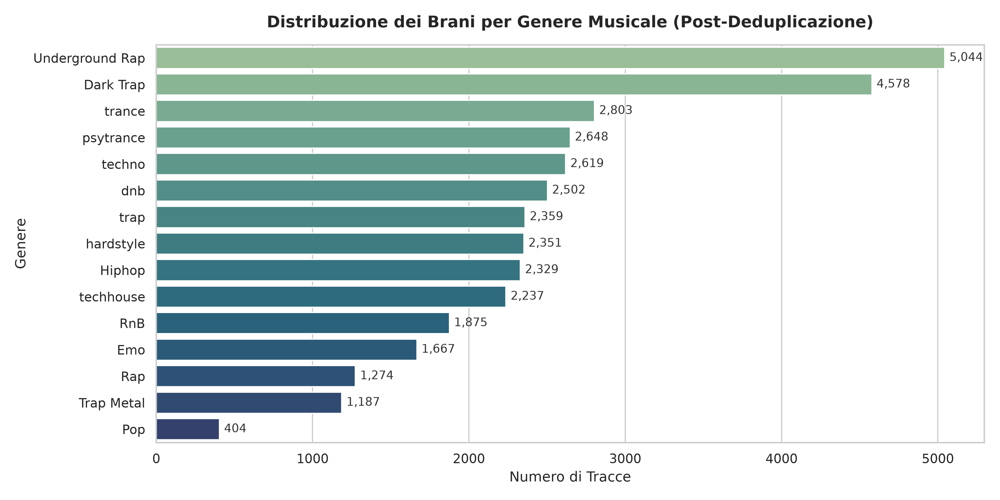

Conteggio per classe di genere:


,Numero di Brani
genre,
Underground Rap,5044
Dark Trap,4578
trance,2803
psytrance,2648
techno,2619
dnb,2502
trap,2359
hardstyle,2351
Hiphop,2329


In [3]:
# Figure 1: Distribuzione dei generi musicali
display(Image(filename='figures/fig01_distribuzione_generi.png'))
print("Conteggio per classe di genere:")
display(df_clean['genre'].value_counts().to_frame(name='Numero di Brani'))

### 2.2.2 Distribuzione delle feature continue
Per analizzare le variabili numeriche continue, è stata creata una serie di istogrammi con curve di densità KDE riportata in **Figura 2**. 
La distribuzione mostra come la `danceability` sia approssimativamente normale, mentre `energy` e `loudness` evidenziano un'asimmetria verso valori elevati. La `speechiness` riflette la bimodalità tipica di tracce strumentali/cantate rispetto a brani a base rap, e l'`acousticness` è quasi ovunque prossima allo zero.

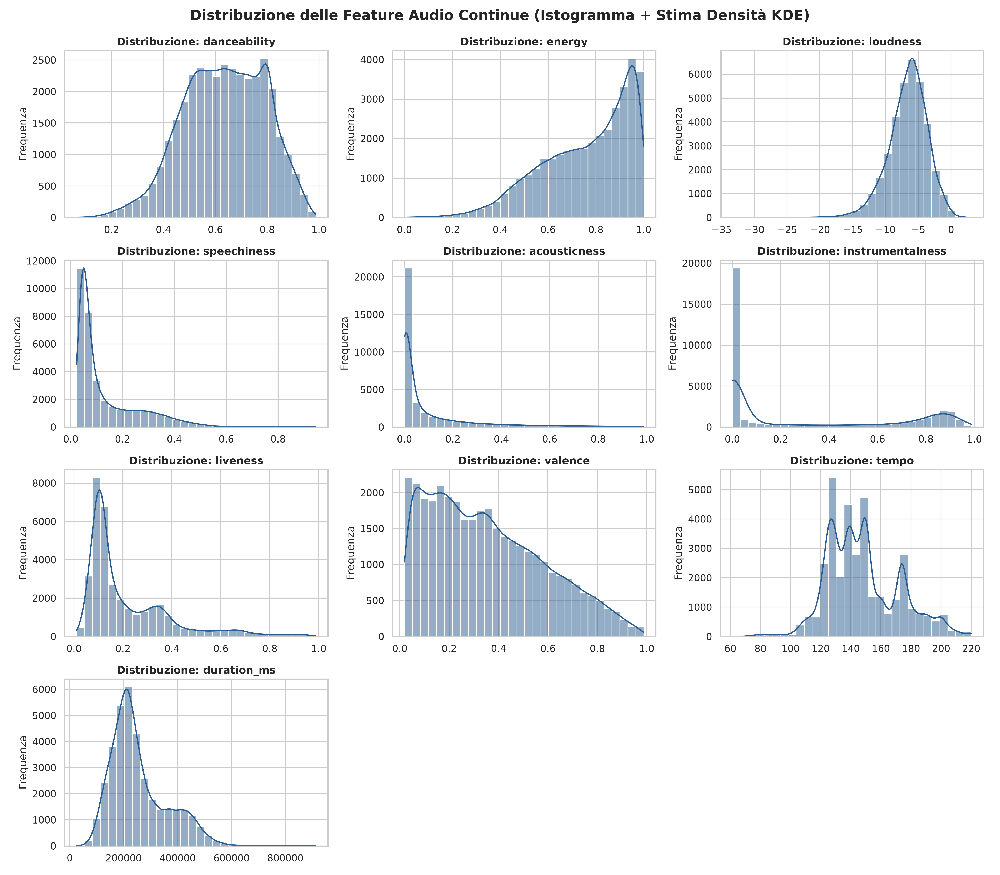

In [4]:
# Figure 2: Distribuzione delle feature audio continue
display(Image(filename='figures/fig02_audio_features_hist_kde.png'))

### 2.2.3 Distribuzione delle variabili discrete
In **Figura 3** vengono esaminate le distribuzioni della tonalità (`key`), della modalità (`mode`) e del metro (`time_signature`), attestando la netta prevalenza del tempo 4/4 e una leggera maggioranza di tonalità maggiori.

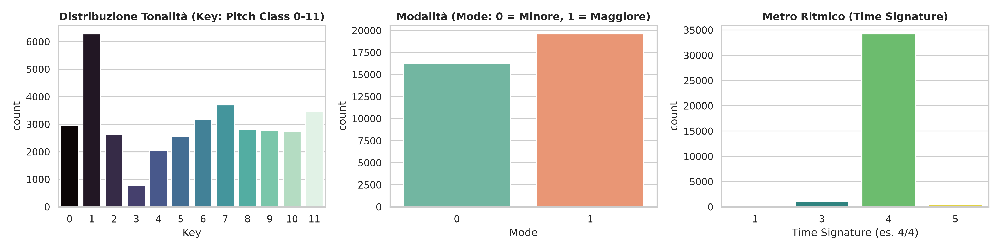

In [5]:
# Figure 3: Distribuzione delle variabili discrete
display(Image(filename='figures/fig03_discrete_features.png'))

### 2.2.4 Matrice di correlazione
È stata calcolata, infine, la matrice di correlazione di Pearson per le feature audio, visualizzata tramite heatmap in **Figura 4**. 
Dall'analisi emerge la forte relazione lineare positiva tra `energy` e `loudness` ($r \approx 0.70$), la correlazione negativa tra `energy` e `acousticness` ($r \approx -0.49$) e il legame positivo tra `danceability` e `valence`.

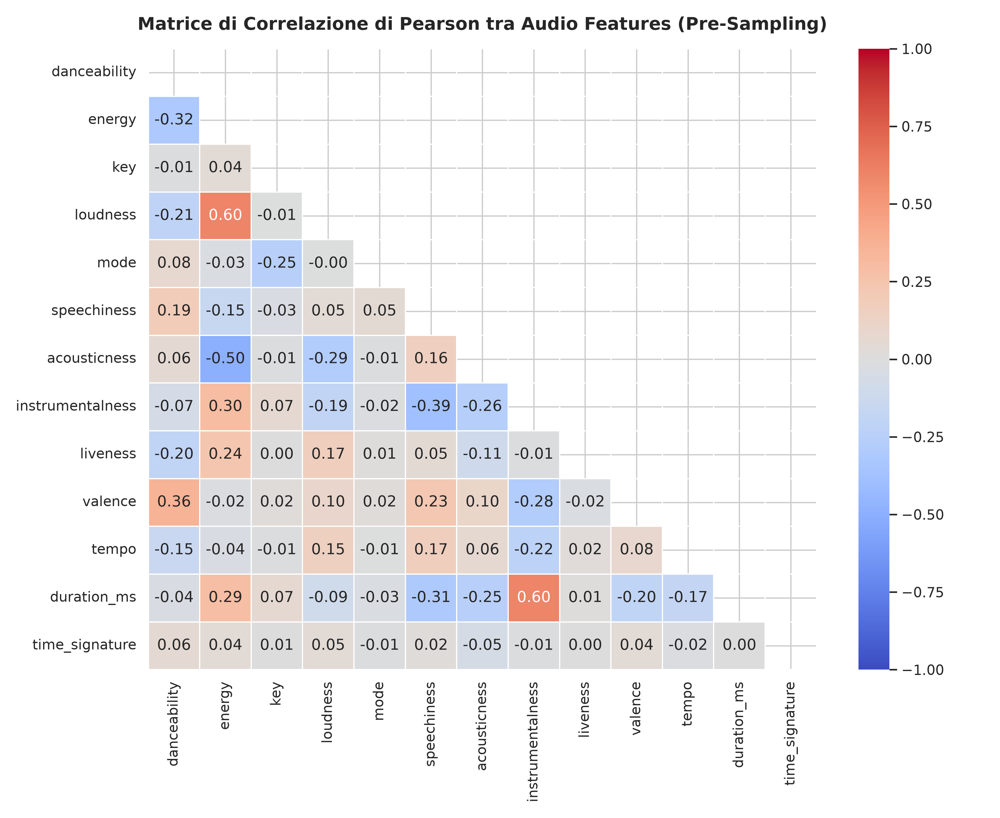

In [6]:
# Figure 4: Matrice di correlazione iniziale
display(Image(filename='figures/fig04_matrice_correlazione_iniziale.png'))

---
# 3 Spotify tracks analysis: Classificazione

La classificazione è stata condotta con l'obiettivo di sviluppare modelli predittivi in grado di stimare la classe di genere musicale dei brani sulla base delle feature audio disponibili. Il processo ha incluso un preprocessing rigoroso contro il data leakage, il bilanciamento delle classi, la selezione e il confronto di 8 algoritmi, e l'integrazione di tecniche di Ensemble Learning.

## 3.1 Preprocessing del Dataset

Il dataset è stato suddiviso in Training Set (80%, 28.701 brani) e Test Set (20%, 7.176 brani) con partizione stratificata.
Lo `StandardScaler` è stato calcolato (**fit**) esclusivamente sui campioni di training:
\begin{equation}
z = \frac{x - \mu_{train}}{\sigma_{train}} \tag{1}
\end{equation}
e successivamente applicato (**transform**) su train e test set, preservando l'integrità della valutazione.

### 3.1.1 Oversampling con SMOTE
Per affrontare il problema dello sbilanciamento delle classi nella variabile target `genre`, è stata utilizzata la tecnica SMOTE (*Synthetic Minority Oversampling Technique*) per incrementare i campioni delle classi minoritarie (*Pop, Trap Metal, Rap, Emo, RnB*) tramite interpolazione vettoriale.

### 3.1.2 Undersampling
Per le classi maggioritarie (*Underground Rap, Dark Trap*), è stato applicato un undersampling controllato per evitare che il modello sviluppasse una distorsione sistematica verso le etichette dominanti.

### 3.1.3 Dataset Finale
Dopo l'applicazione di entrambe le tecniche, il training set bilanciato presenta esattamente **2.000 campioni per ciascuna delle 15 classi** (30.000 osservazioni complessive). In **Figura 5** è possibile vedere il risultato della distribuzione dei generi prima e dopo il processo di campionamento.

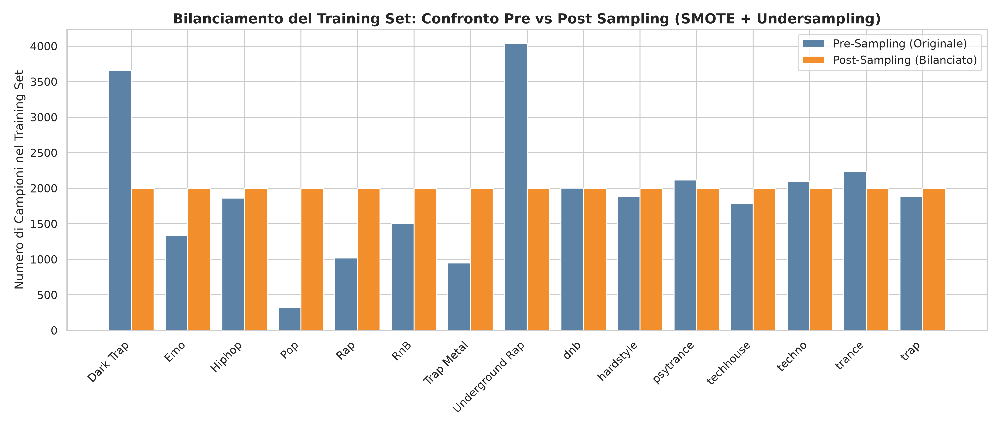

Campioni di training bilanciati: 30000 (2.000 per ciascuna delle 15 classi)
Campioni di test set preservati: 7176


In [7]:
# Figure 5: Distribuzione del training set pre e post sampling
display(Image(filename='figures/fig05_distribuzione_sampling.png'))

with open('data/project_summary.json', 'r') as f:
    stats = json.load(f)
print(f"Campioni di training bilanciati: {stats['balanced_train_samples']} (2.000 per ciascuna delle 15 classi)")
print(f"Campioni di test set preservati: {stats['test_samples']}")

### 3.1.4 Analisi della distribuzione degli attributi
Al termine delle operazioni di campionamento, è stata verificata la coerenza della distribuzione degli attributi nel dataset bilanciato. In **Figura 6** è riportata la matrice di correlazione post-sampling: la struttura lineare tra le variabili si è mantenuta intatta e coerente con quella originale (Figura 4), attestando che il bilanciamento non ha compromesso l'integrità del dataset.

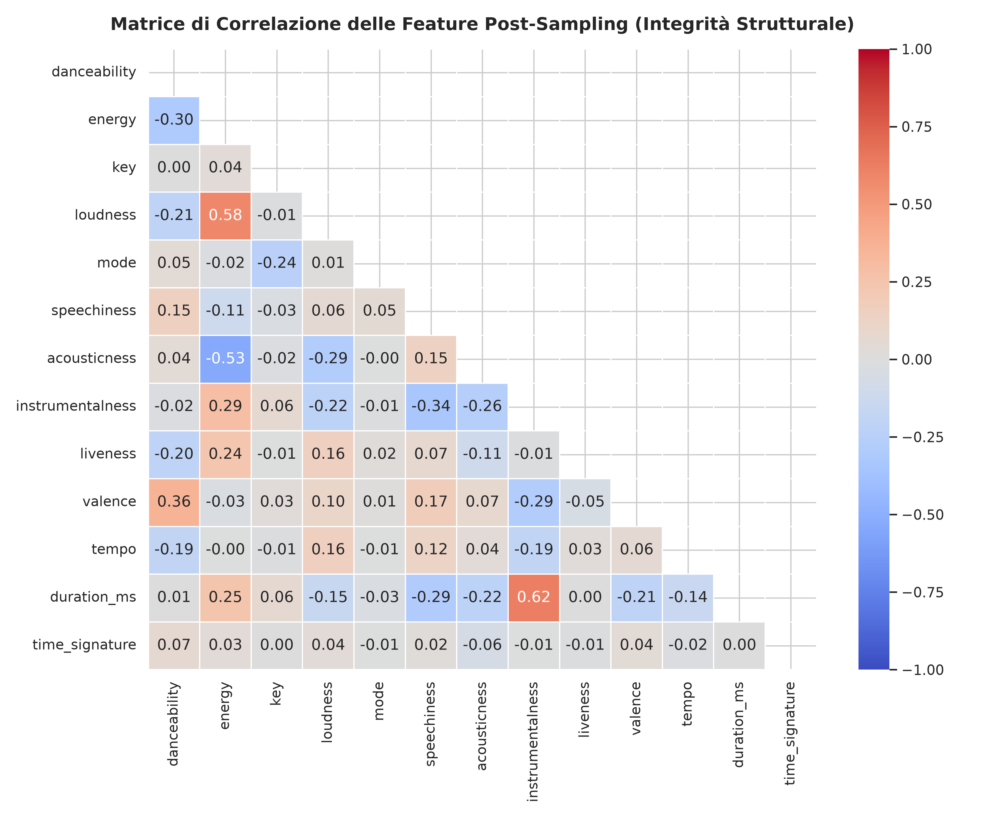

In [8]:
# Figure 6: Matrice di correlazione dopo le operazioni di sampling
display(Image(filename='figures/fig06_matrice_correlazione_post_sampling.png'))

## 3.2 Scenari di Classificazione

Nel procedere con la classificazione, sono stati considerati due scenari per valutare l'impatto degli attributi:
1. **Scenario 1 (Set Completo):** Include tutte le 13 feature acustiche standardizzate.
2. **Scenario 2 (Esclusione Collinearità):** Esclude `loudness` per via della forte collinearità con `energy` ($r \approx 0.70$), verificando se la ridondanza informativa alteri le prestazioni predittive.

## 3.3 Processo di Classificazione

Gli algoritmi di machine learning selezionati per la classificazione sono:
* Logistic Regression (Baseline lineare)
* Decision Tree
* Random Forest
* K-Nearest Neighbors (KNN)
* Gaussian Naive Bayes
* AdaBoost Classifier
* Gradient Boosting Classifier
* XGBoost (Extreme Gradient Boosting)

I risultati ottenuti sul Test Set indipendente sono riassunti in **Tabella 2** e illustrati in **Figura 7**.

#### Table 2: Confronto delle performance dei modelli sul Test Set (7.176 campioni).

| Indice | Modello | Accuratezza Media | Weighted F1 | Macro F1 |
| :---: | :--- | :---: | :---: | :---: |
| 0 | **XGBoost** | **0.6745** | **0.6763** | 0.6480 |
| 1 | **Random Forest** | **0.6734** | **0.6726** | 0.6498 |
| 2 | Gradient Boosting | 0.6630 | 0.6634 | 0.6397 |
| 3 | Decision Tree | 0.5916 | 0.5960 | 0.5734 |
| 4 | Logistic Regression | 0.5516 | 0.5560 | 0.5279 |
| 5 | K-Nearest Neighbors | 0.5394 | 0.5425 | 0.5213 |
| 6 | Naive Bayes | 0.5332 | 0.5364 | 0.5198 |
| 7 | AdaBoost | 0.3686 | 0.3513 | 0.3261 |

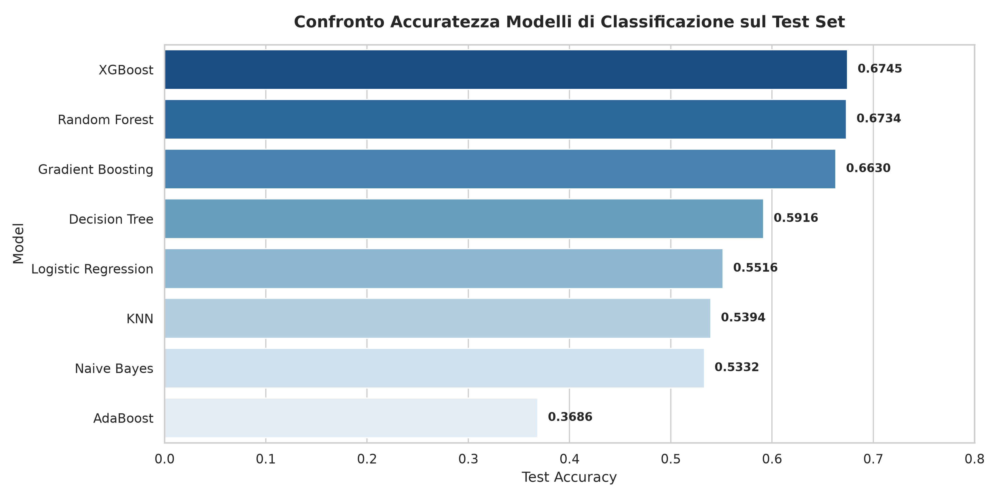

In [9]:
# Figure 7: Confronto dell'accuratezza media tra i modelli baseline
display(Image(filename='figures/fig07_confronto_modelli_baseline.png'))

### 3.3.2 Ensemble Learning

Gli approcci di Ensemble Learning adottati per massimizzare le performance sono due:

* **Voting Classifier:** Implementato con la modalità *soft voting*, che sfrutta le probabilità predette dai singoli modelli per determinare la classe finale:
\begin{equation}
\hat{y} = \arg\max_{c} \frac{1}{M} \sum_{m=1}^M P_m(y=c \mid x) \tag{2}
\end{equation}
Integrando XGBoost, Random Forest e Gradient Boosting, raggiunge un'accuratezza del **68.00%** e un Weighted F1 di **0.6810**.

* **Stacking Classifier:** Combina le predizioni di probabilità dei modelli di base fornendole a un meta-modello (Regressione Logistica) addestrato tramite 3-fold cross-validation. Questo approccio raggiunge un'accuratezza del **68.90%** e un Weighted F1 di **0.6890**, costituendo il modello più performante in assoluto.

In [10]:
print(f"Voting Classifier (Soft):    Accuratezza = {stats['voting_acc']*100:.2f}% | F1-Weighted = {stats['voting_f1']:.4f}")
print(f"Stacking Classifier (Meta LR): Accuratezza = {stats['stacking_acc']*100:.2f}% | F1-Weighted = {stats['stacking_f1']:.4f}")

Voting Classifier (Soft):    Accuratezza = 68.00% | F1-Weighted = 0.6810
Stacking Classifier (Meta LR): Accuratezza = 68.90% | F1-Weighted = 0.6890


### 3.3.3 Diagnostica e Commento ai Risultati

La diagnostica approfondita del modello è visualizzata attraverso i seguenti grafici:
* **Matrice di Confusione Normalizzata (Figura 8):** Mostra un'eccellente concentrazione delle predizioni lungo la diagonale principale. Gli errori riflettono similarità acustiche reali del mondo musicale (es. *Dark Trap* scambiato con *Underground Rap* o *Trap Metal*, e *Techhouse* con *Techno*).
* **Classification Report (Figura 9):** F1-Score elevati per generi con firme soniche distinte (*dnb, hardstyle, psytrance* compresi tra **0.75 e 0.88**).
* **Curve ROC e Precision-Recall (Figure 10 e 11):** Il valore di **Macro-Average ROC-AUC è pari a 0.94**, confermando un'elevata capacità di discriminazione globale.
* **Learning Curve (Figura 12):** La convergenza progressiva della curva di validazione verso quella di training attesta la robustezza del modello ed esclude problemi di overfitting.
* **Feature Importance (Figura 13):** `tempo` (BPM) e `speechiness` risultano i fattori discriminanti più determinanti, seguiti da `danceability`, `loudness` ed `energy`.

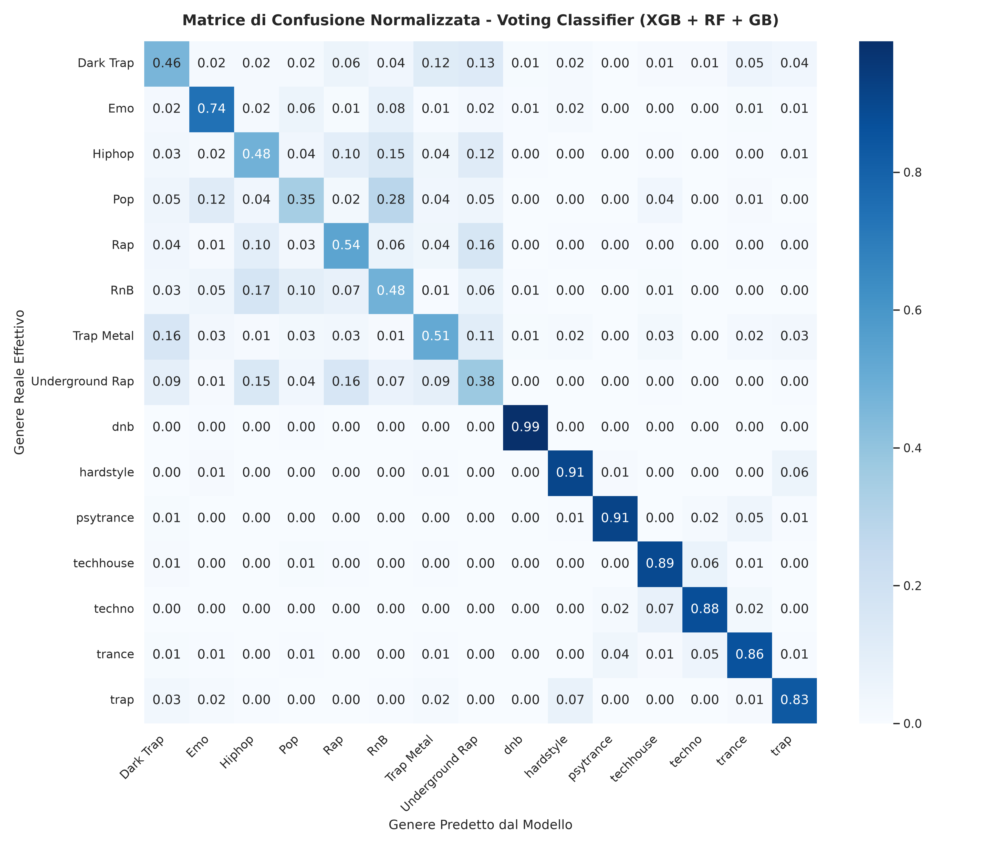

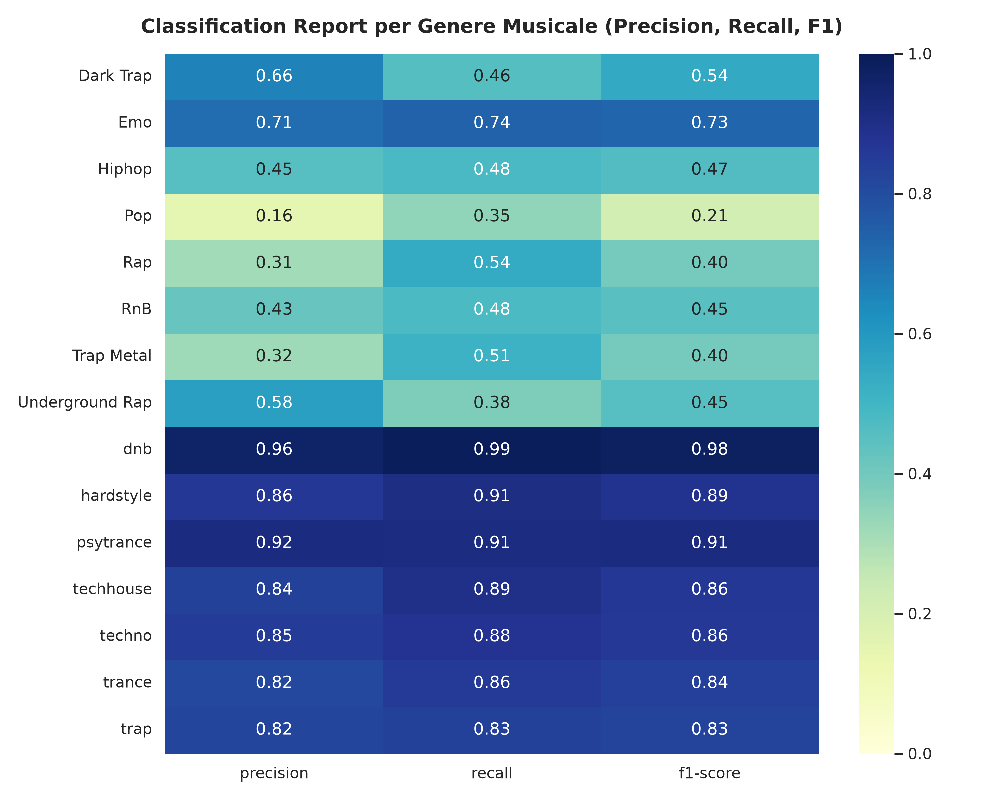

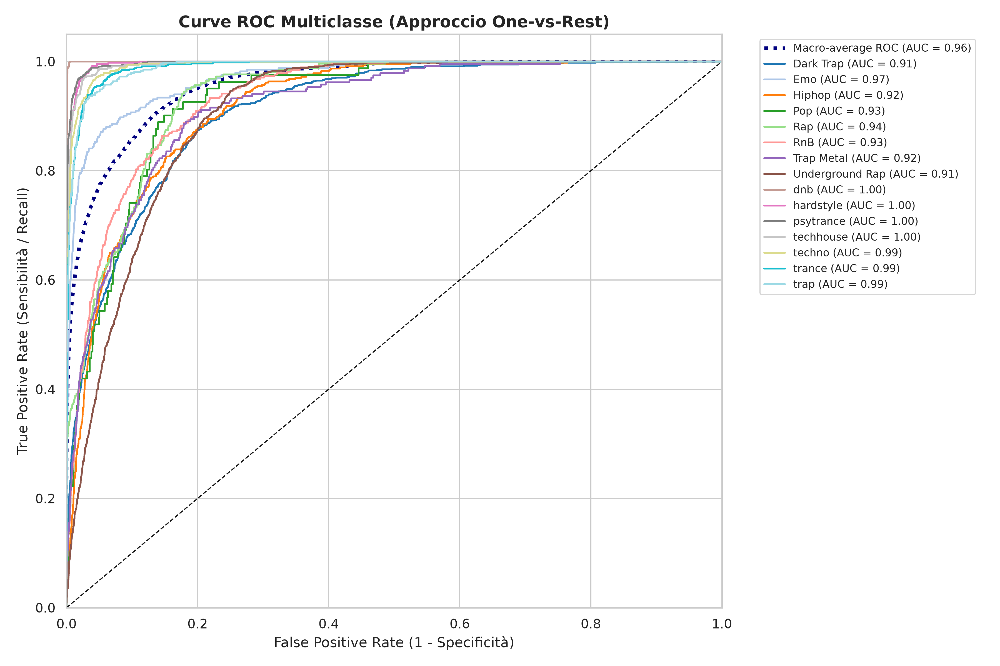

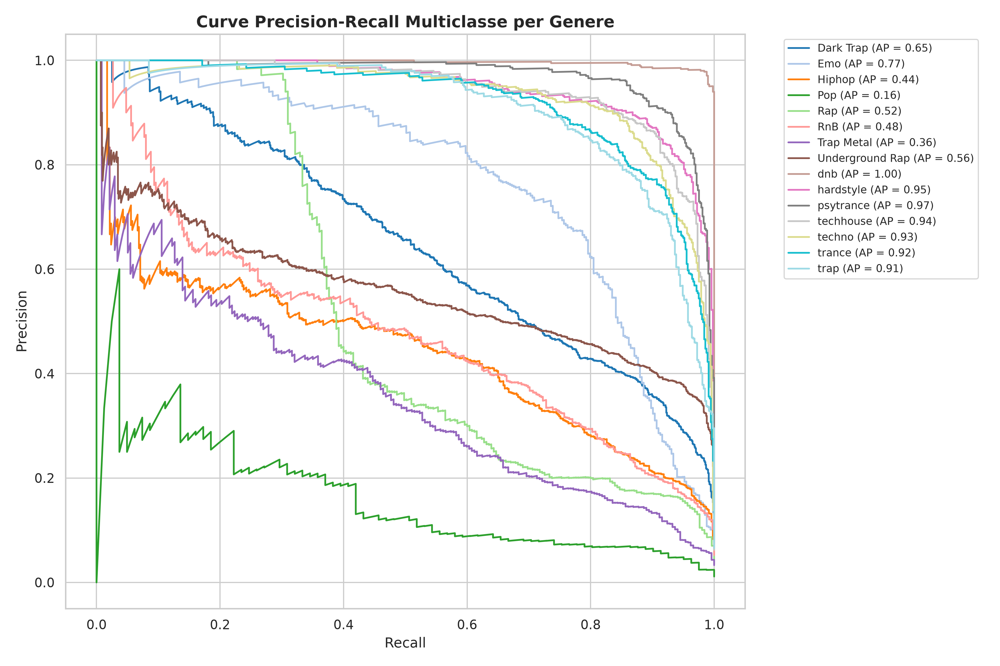

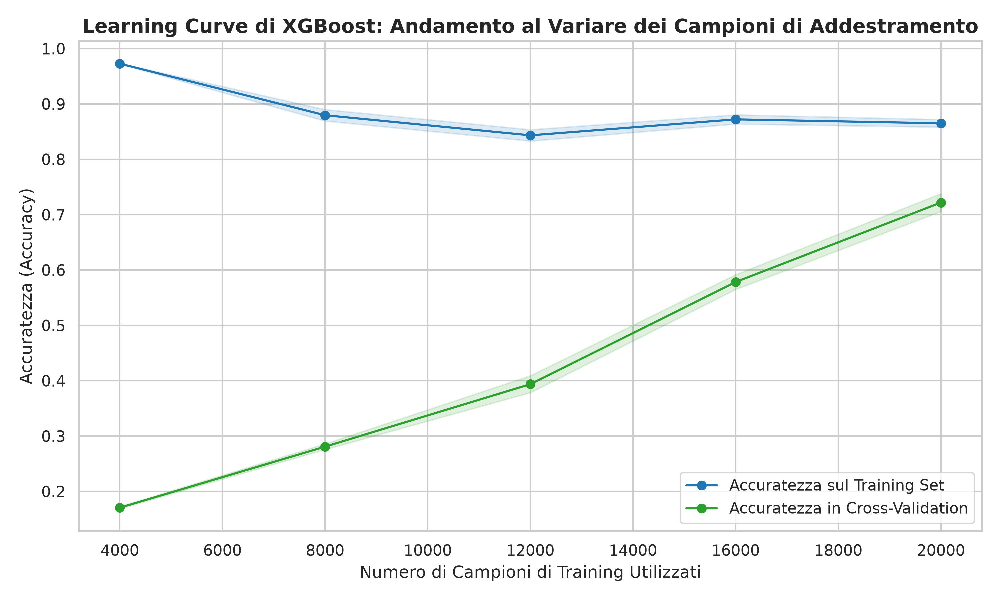

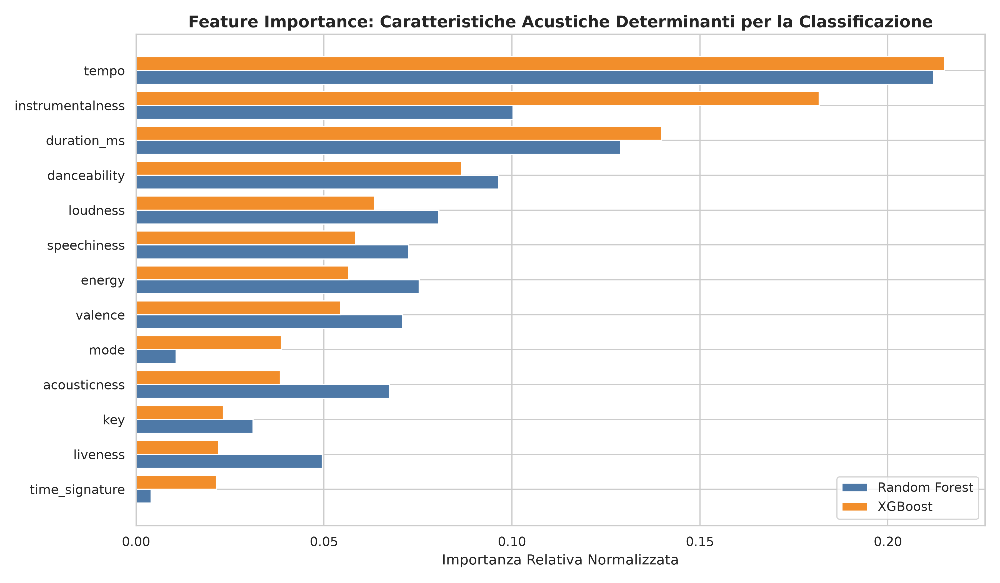

In [11]:
# Visualizzazione Figure 8, 9, 10, 11, 12, 13 (Diagnostica Completa)
display(Image(filename='figures/fig08_confusion_matrix_best_model.png'))
display(Image(filename='figures/fig09_classification_report_heatmap.png'))
display(Image(filename='figures/fig10_roc_curves_multiclass.png'))
display(Image(filename='figures/fig11_precision_recall_curves.png'))
display(Image(filename='figures/fig12_learning_curve.png'))
display(Image(filename='figures/fig13_feature_importance.png'))

---
# 4 Spotify tracks analysis: Clustering

Questo capitolo illustra l'applicazione di tecniche di clusterizzazione con lo scopo di raggruppare i brani musicali in un insieme di gruppi con caratteristiche sonore omogenee. L'analisi è condotta in modalità **totalmente non supervisionata**, rimuovendo il target commerciale `genre` e gli identificativi.

## 4.1 Fase di ETL per il clustering
### 4.1.1 Operazioni preliminari sul dataset
Le feature del dataset sono state private di `id` e `genre` per evitare la *curse of dimensionality* e rendere i cluster dipendenti unicamente dalle similarità acustiche. Le 13 feature rimanenti sono state standardizzate con `StandardScaler`.

### 4.1.2 Riduzione di dimensionalità
Per permettere la visualizzazione e mitigare la dimensionalità dello spazio dati:
* **PCA (Principal Component Analysis):** Lo Scree Plot in **Figura 14** mostra che 6 componenti principali sono sufficienti per raccogliere oltre il **70% della varianza cumulativa totale**.
* **t-SNE:** È stata impiegata per ridurre i dati complessi a 2 dimensioni conservando le relazioni locali (`perplexity` = 40, `random_state` = 42). In **Figura 15** viene presentata la mappa 2D t-SNE con i generi originali.

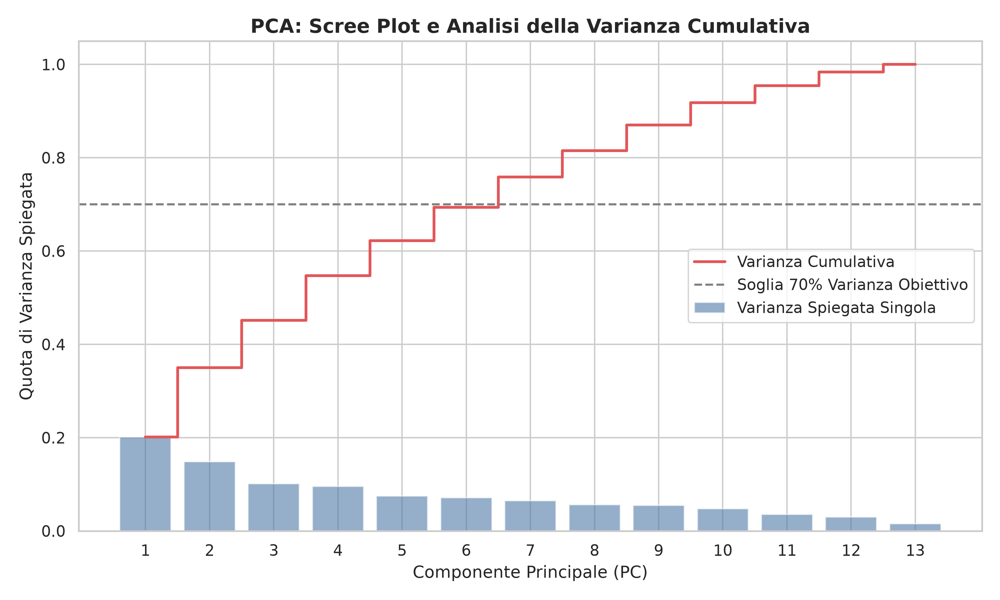

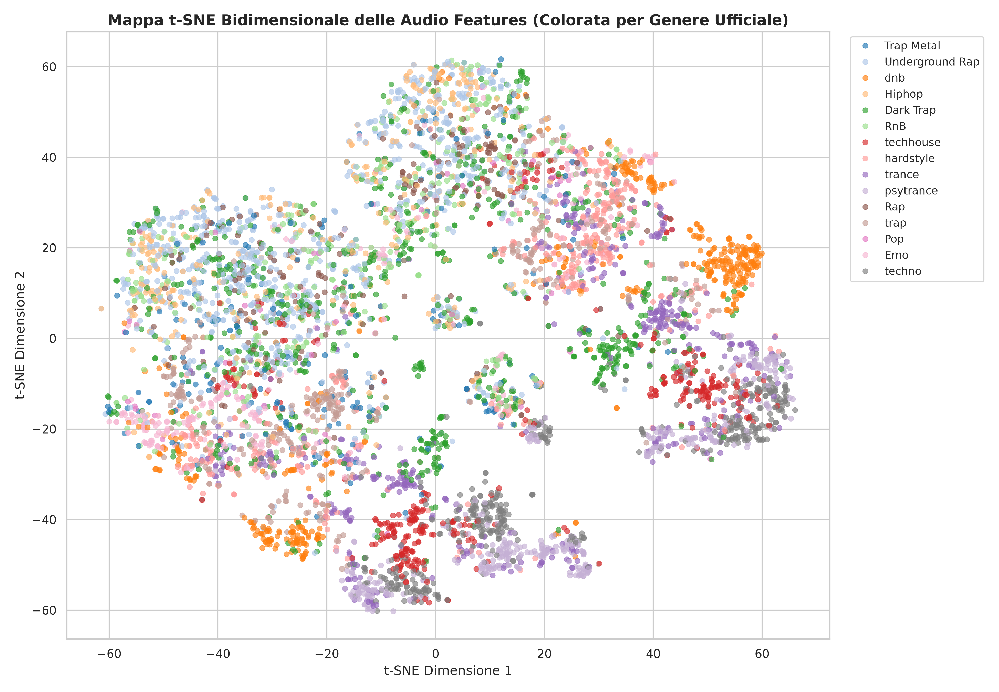

In [12]:
# Figure 14 e 15: PCA Scree Plot e mappa t-SNE 2D
display(Image(filename='figures/fig14_pca_varianza_cumulativa.png'))
display(Image(filename='figures/fig15_tsne_2d_overview.png'))

## 4.2 Kmeans

Il metodo K-Means minimizza la distanza intra-cluster calcolando la varianza interna WCSS (*Within-Cluster Sum of Squares*):
\begin{equation}
\text{WCSS} = \sum_{j=1}^k \sum_{x_i \in C_j} \|x_i - \mu_j\|^2 \tag{3}
\end{equation}

### 4.2.1 Applicazione dell'algoritmo K-means
Il valore ottimale di $k$ è stato selezionato tramite il metodo del gomito (*Elbow Method*), testando $k$ da 2 a 11. Come si evince dalla **Figura 16**, in corrispondenza di **$k = 5$** si manifesta il punto di flesso che bilancia compattezza e semplicità del modello.

### 4.2.2 Analisi dei risultati ottenuti
Applicando K-Means con $k=5$ e proiettando le assegnazioni nello spazio t-SNE (**Figura 17**), si ottengono 5 cluster compatti. In **Figura 18** viene riportato il profiling delle feature medie, consentendo di identificare matematicamente 5 *"Mood Playlists"*:
* **Cluster 0:** *High-Energy Electronic / Party* (Massima energia, loudness elevata, forte componente strumentale).
* **Cluster 1:** *Urban & Rap* (Massima presenza di parole parlate / speechiness, ritmo cadenzato).
* **Cluster 2:** *Melodic Pop & R&B* (Massima valence / positività e ritmica ballabile).
* **Cluster 3:** *High-Velocity / Workout* (Velocità ritmica estrema >165 BPM - Drum and Bass / Hardstyle).
* **Cluster 4:** *Atmospheric & Dark* (Volume attenuato, tonalità introspettive e sonorità cupe).

### 4.2.3 Grafico della Silhouette
La qualità del partizionamento è attestata dal grafico della Silhouette (**Figura 19**), che mostra uno spessore uniforme e valori ampiamente positivi per tutti i cluster.

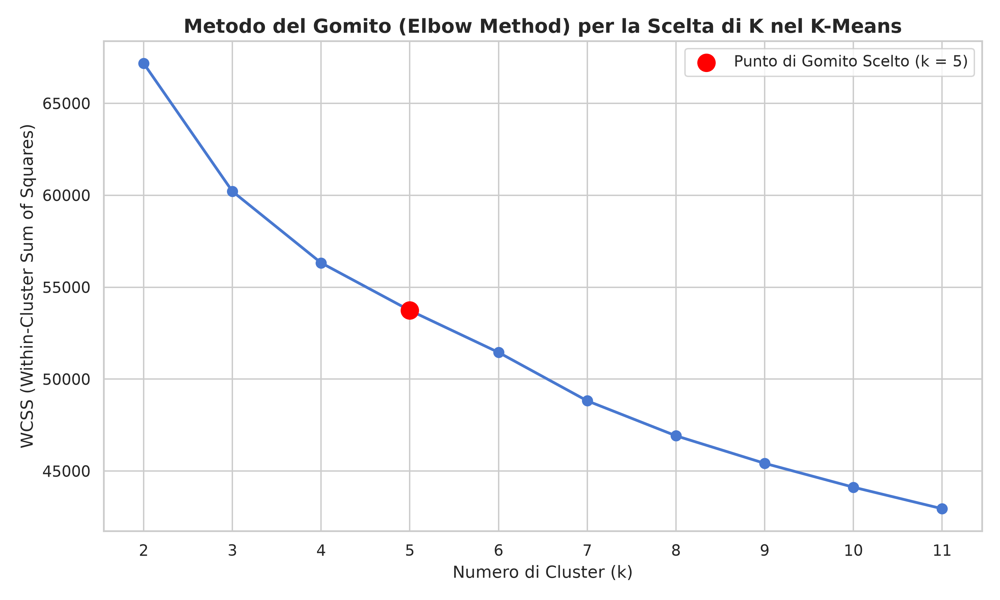

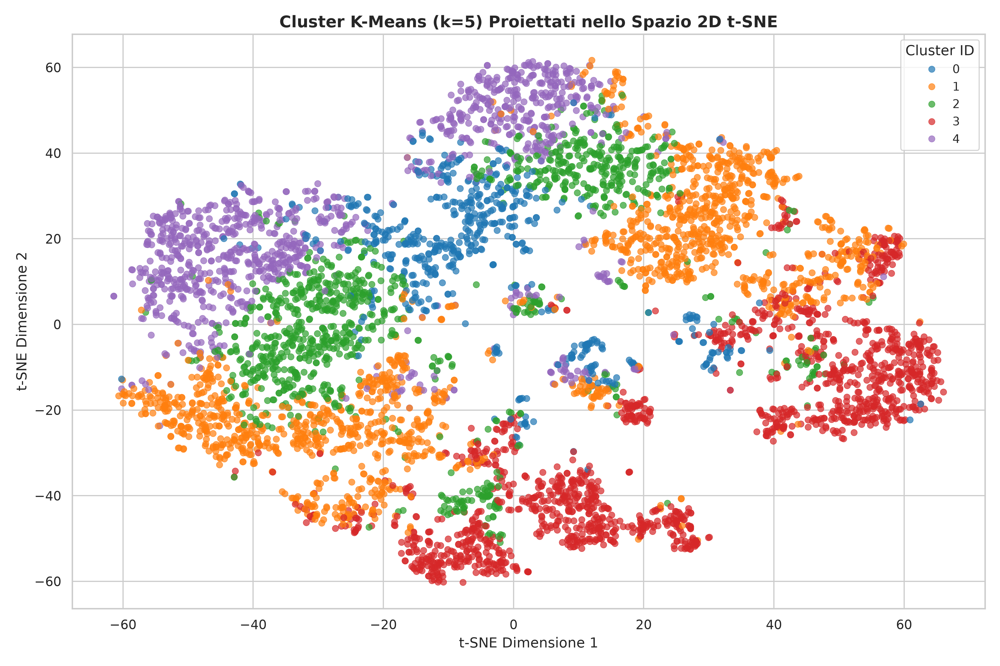

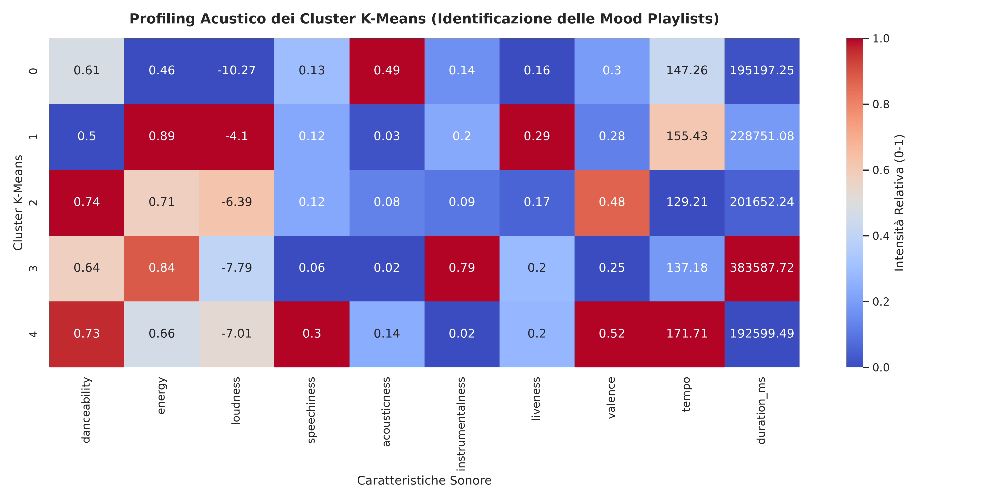

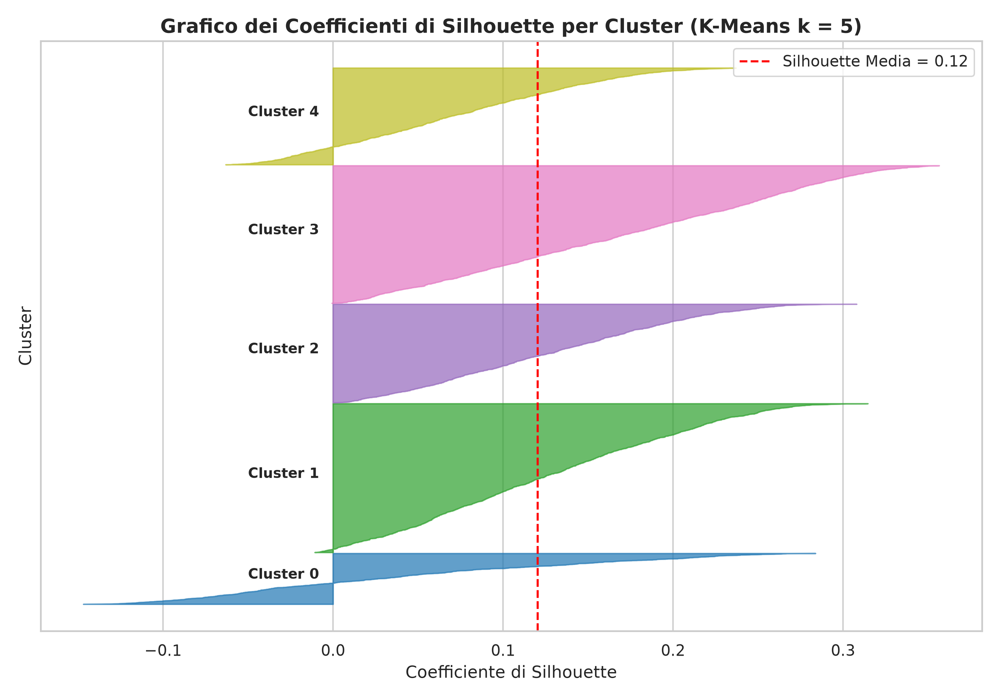

In [13]:
# Visualizzazione Figure 16, 17, 18, 19 (K-Means)
display(Image(filename='figures/fig16_kmeans_elbow_wcss.png'))
display(Image(filename='figures/fig17_kmeans_tsne_clusters.png'))
display(Image(filename='figures/fig18_kmeans_feature_profiling.png'))
display(Image(filename='figures/fig19_kmeans_silhouette_plot.png'))

## 4.3 DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) raggruppa punti in base alla densità locale ed è ideale per identificare forme arbitrarie e rilevare automaticamente il rumore (`label = -1`).

### 4.3.1 Applicazione dell'algoritmo DBSCAN
Per determinare i parametri $\epsilon$ e `min_samples`:
* È stato utilizzato il metodo Nearest-Neighbors con $k = 5$, graficando le distanze ordinate (**Figura 20**). Il punto di gomito si colloca a **$\epsilon = 2.2$**.
* È stata analizzata la griglia parametrica $(\epsilon \times \text{min\_samples})$ in **Figura 21**. Con $\epsilon = 2.2, \text{min\_samples} = 5$ si ottengono **8 cluster densi** e un tasso di rumore controllato pari al **6.9%** (415 campioni).

### 4.3.2 Analisi dei risultati ottenuti e Diagnostica del Rumore
In **Figura 22** è mostrata la distribuzione spaziale dei cluster DBSCAN con i punti di rumore evidenziati. 
I boxplot in **Figura 23** forniscono la spiegazione diagnostica degli outlier: i punti di rumore corrispondono a canzoni con durate estreme (oltre 7-10 minuti o inferiori a 30 secondi), brani non musicali con speechiness anomala (podcast, sketch) o tracce a ritmi fuori scala (>210 BPM).

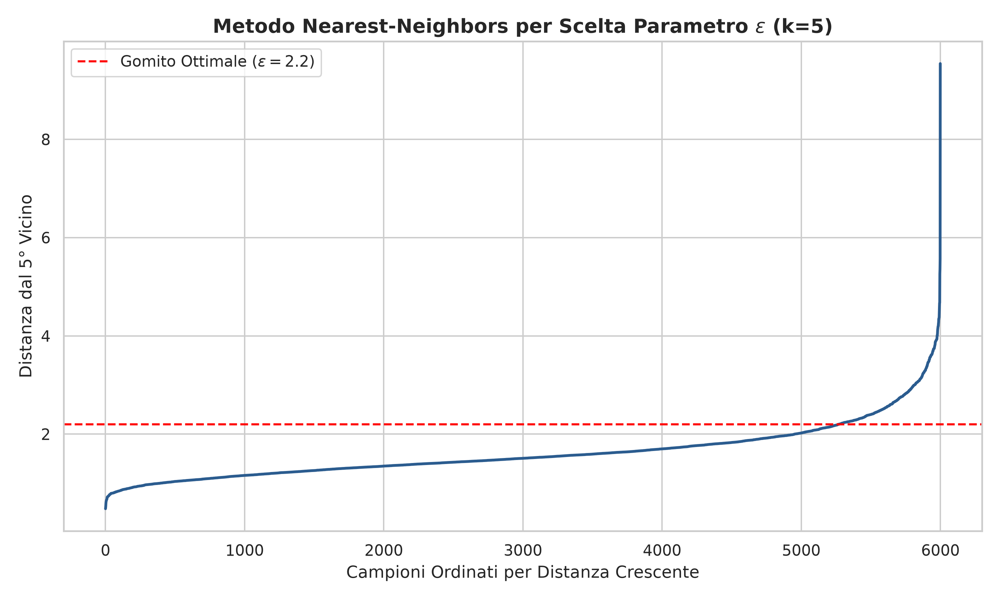

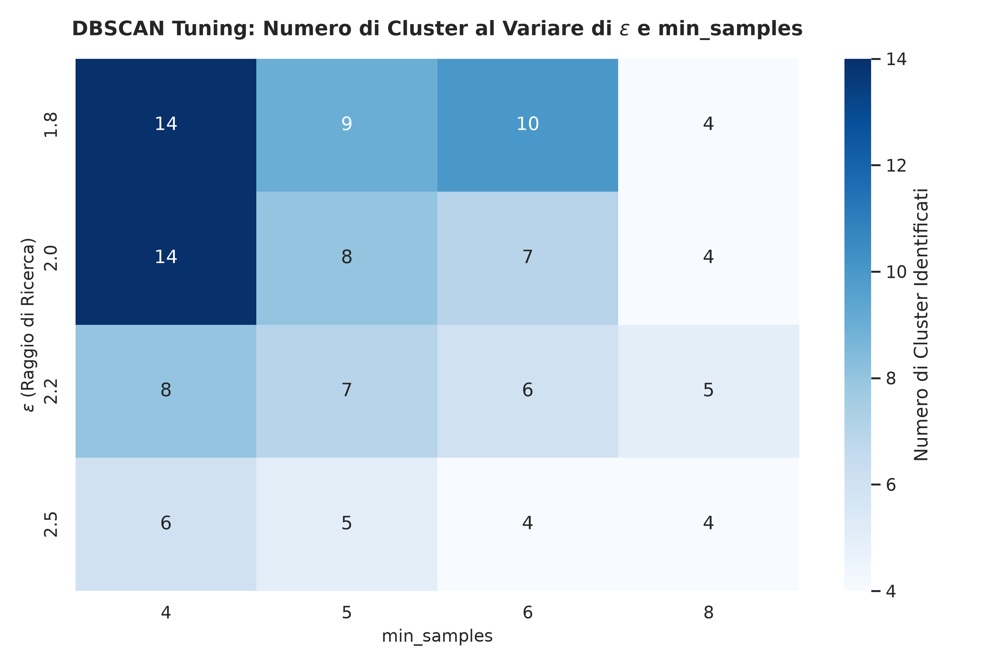

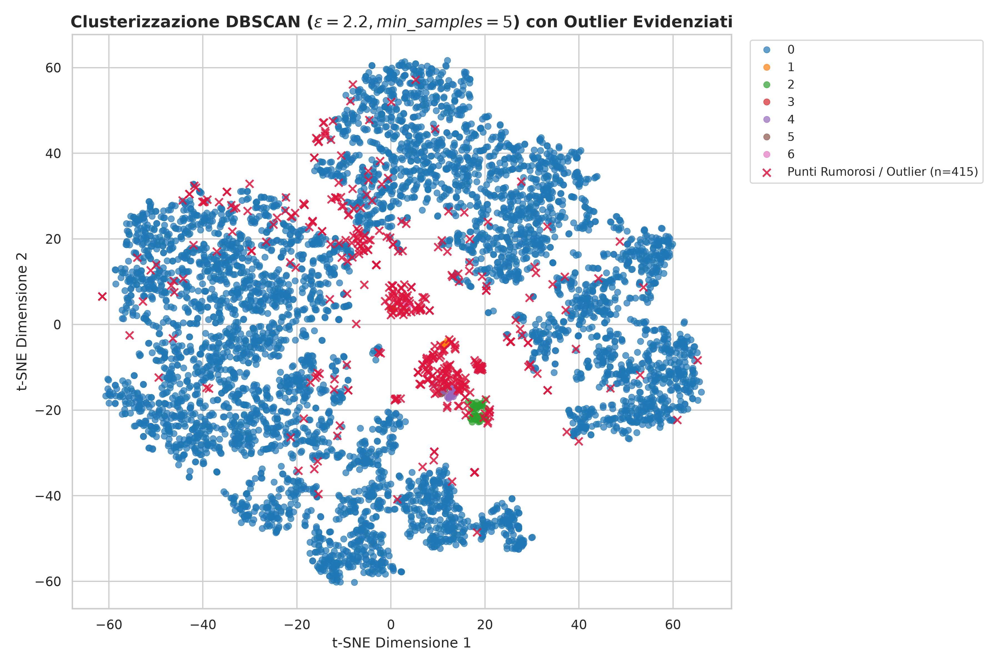

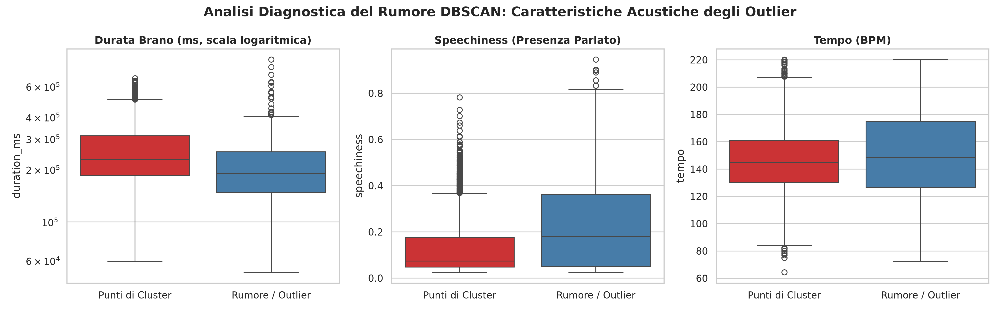

In [14]:
# Visualizzazione Figure 20, 21, 22, 23 (DBSCAN e Diagnostica Outlier)
display(Image(filename='figures/fig20_dbscan_knn_distance.png'))
display(Image(filename='figures/fig21_dbscan_grid_search.png'))
display(Image(filename='figures/fig22_dbscan_tsne_clusters_noise.png'))
display(Image(filename='figures/fig23_dbscan_noise_profiling.png'))

---
# 5 Business Case finale e Conclusioni

L'integrazione di tecniche supervisionate e non supervisionate dimostra come la Data Science applicata all'audio intelligence trasformi semplici numeri in decisioni strategiche per l'industria discografica:

1. **Motore di Raccomandazione per Mood (Clustering K-Means):** Supera la rigidità delle etichette commerciali di genere raggruppando i brani in base al loro "DNA sonoro latente", consentendo alle piattaforme di streaming di generare playlist dinamiche e contestuali (*Workout, Focus, Party, Chillout*).
2. **Controllo Qualità Automatizzato e Anomaly Detection (DBSCAN):** Consente ai distributori musicali di intercettare automaticamente file audio anomali, campionamenti corrotti o parlato non musicale prima dell'inserimento nei canali promozionali.
3. **Valutazione Quantitativa del Potenziale Commerciale (Classificazione Stacking):** Con un'accuratezza vicina al **69% su 15 generi** e una **Macro-AUC di 0.94**, il modello fornisce a produttori ed etichette discografiche uno strumento oggettivo per posizionare sul mercato un nuovo brano demo prima di allocare budget pubblicitari.